(78682, 21)
  company_name status_label  year       X1       X2      X3      X4       X5  \
0          C_1        alive  1999  511.267  833.107  18.373  89.031  336.018   
1          C_1        alive  2000  485.856  713.811  18.577  64.367  320.590   
2          C_1        alive  2001  436.656  526.477  22.496  27.207  286.588   
3          C_1        alive  2002  396.412  496.747  27.172  30.745  259.954   
4          C_1        alive  2003  432.204  523.302  26.680  47.491  247.245   

       X6       X7  ...        X9      X10      X11     X12      X13      X14  \
0  35.163  128.348  ...  1024.333  740.998  180.447  70.658  191.226  163.816   
1  18.531  115.187  ...   874.255  701.854  179.987  45.790  160.444  125.392   
2 -58.939   77.528  ...   638.721  710.199  217.699   4.711  112.244  150.464   
3 -12.410   66.322  ...   606.337  686.621  164.658   3.573  109.590  203.575   
4   3.504  104.661  ...   651.958  709.292  248.666  20.811  128.656  131.261   

       X15       X16

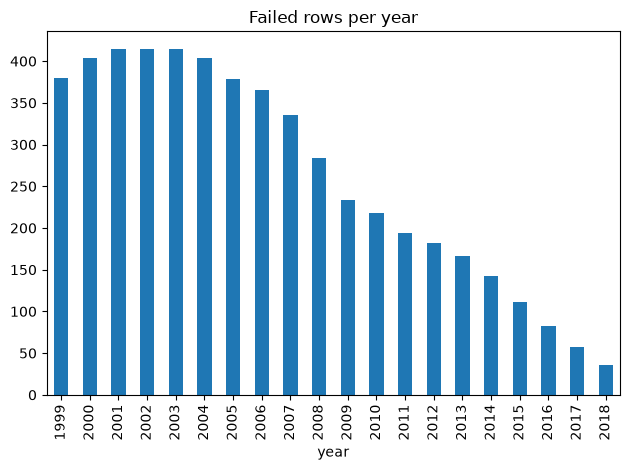

                             count         mean           std          min  \
current_assets             78682.0   880.362485   3928.564794      -7.7600   
cogs                       78682.0  1594.529029   8930.484664    -366.6450   
depreciation_amortization  78682.0   121.234256    652.376804       0.0000   
ebitda                     78682.0   376.759424   2012.023142  -21913.0000   
inventory                  78682.0   201.605717   1060.766096       0.0000   
net_income                 78682.0   129.382453   1265.532022  -98696.0000   
total_receivables          78682.0   286.832743   1335.978571      -0.0060   
market_value               78682.0  3414.354610  18414.103647       0.0001   
net_sales                  78682.0  2364.019706  11950.068842   -1964.9990   
total_assets               78682.0  2867.110620  12917.944421       0.0010   
long_term_debt             78682.0   722.483710   3242.170946      -0.0230   
ebit                       78682.0   255.525035   1494.643534  -

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
 
PATH = "american_bankruptcy.csv"   # change if your file is elsewhere
df = pd.read_csv(PATH)
print(df.shape)
print(df.head())
print(df.dtypes)
 
# %% Rename X1..X18 (VERIFY this mapping against the dataset's Kaggle description)
names = {
    "X1": "current_assets",
    "X2": "cogs",
    "X3": "depreciation_amortization",
    "X4": "ebitda",
    "X5": "inventory",
    "X6": "net_income",
    "X7": "total_receivables",
    "X8": "market_value",
    "X9": "net_sales",
    "X10": "total_assets",
    "X11": "long_term_debt",
    "X12": "ebit",
    "X13": "gross_profit",
    "X14": "current_liabilities",
    "X15": "retained_earnings",
    "X16": "total_revenue",
    "X17": "total_liabilities",
    "X18": "operating_expenses",
}
df = df.rename(columns=names)
 
# %% Basic quality checks
print("Missing values per column:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Companies:", df["company_name"].nunique())
print("Years:", df["year"].min(), "to", df["year"].max())
 
# %% Class balance (rows and companies)
print(df["status_label"].value_counts())
print(df["status_label"].value_counts(normalize=True).round(4))
failed_firms = df.loc[df["status_label"] == "failed", "company_name"].nunique()
print("Distinct failed companies:", failed_firms)
 
# %% KEY CHECK: how are failed companies labelled across their years?
# Is only the last year 'failed', or are several years 'failed'?
rows_per_company = df.groupby("company_name").size()
failed_rows_per_company = (
    df[df["status_label"] == "failed"].groupby("company_name").size()
)
print("Failed rows per failed company:\n",
      failed_rows_per_company.value_counts().sort_index())
 
# Look at a few failed companies year by year
sample = df[df["status_label"] == "failed"]["company_name"].drop_duplicates().head(3)
for c in sample:
    print(df[df["company_name"] == c][["company_name", "year", "status_label"]]
          .sort_values("year").to_string(index=False))
 
# %% Years of history per company
print(rows_per_company.describe())
print(rows_per_company.value_counts().sort_index())
 
# %% Failures per year (is the split by year reasonable?)
by_year = df.groupby("year")["status_label"].apply(lambda s: (s == "failed").sum())
print(by_year)
by_year.plot(kind="bar", title="Failed rows per year")
plt.tight_layout()
plt.savefig("failed_per_year.png", dpi=150)
plt.show()
 
# %% Feature summary, negatives and outliers
num_cols = list(names.values())
print(df[num_cols].describe().T)
print("Negative values per column:\n", (df[num_cols] < 0).sum())
 
# %% Check the predefined time split sizes
train = df[df["year"] <= 2011]
val = df[(df["year"] >= 2012) & (df["year"] <= 2014)]
test = df[df["year"] >= 2015]
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(n, d.shape, "failed:", (d["status_label"] == "failed").sum())
 

In [1]:
   import os
   print(os.getcwd())


C:\Users\Shreya\Documents\ML Project
